In [1]:
print("Fintech Analytics Project")

Fintech Analytics Project


# Fintech Transaction Analytics

**Goal:** Analyse 5,000 digital payment transactions to find failure and fraud patterns.

**Tools:** Python, pandas, matplotlib

**Data:** Synthetic dataset with 800 customers over 12 months (amounts in INR)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries loaded successfully")

Libraries loaded successfully


In [5]:
tx = pd.read_csv("data/transactions_raw.csv")

In [6]:
tx.shape

(5025, 9)

In [7]:
tx.head()

,txn_id,customer_id,timestamp,amount_inr,payment_method,category,device,status,is_fraud
0,T500105,C1513,2026-04-24 23:45:06,214.30,UPI,Groceries,iOS,Success,0
1,T504168,C1319,2026-03-07 11:13:26,6156.52,Debit Card,Travel,iOS,Success,0
2,T501229,C1222,2026-06-30 01:01:53,2211.26,UPI,Entertainment,Web,Success,0
3,T500588,C1396,2026-01-19 01:51:02,3195.27,UPI,Healthcare,Web,Success,0
4,T500129,C1177,2026-06-22 00:55:05,16960.63,UPI,Travel,Android,Success,1


In [8]:
tx.tail()

,txn_id,customer_id,timestamp,amount_inr,payment_method,category,device,status,is_fraud
5020,T500194,C1513,2026-09-03 10:03:50,8673.62,Wallet,Loan EMI,iOS,Success,0
5021,T504265,C1523,2026-05-25 15:16:01,1452.31,UPI,Shopping,Android,Success,0
5022,T502713,C1209,2025-12-24 13:09:55,1916.06,UPI,Travel,iOS,Success,0
5023,T501022,C1697,2026-02-25 21:52:28,15584.79,Credit Card,Travel,Android,Success,0
5024,T504308,C1275,2026-09-01 13:22:57,1151.17,UPI,Groceries,iOS,Success,0


In [9]:
tx.columns

Index(['txn_id', 'customer_id', 'timestamp', 'amount_inr', 'payment_method',
       'category', 'device', 'status', 'is_fraud'],
      dtype='str')

In [10]:
tx.info()

<class 'pandas.DataFrame'>
RangeIndex: 5025 entries, 0 to 5024
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   txn_id          5025 non-null   str    
 1   customer_id     5025 non-null   str    
 2   timestamp       5025 non-null   str    
 3   amount_inr      5025 non-null   float64
 4   payment_method  5025 non-null   str    
 5   category        4985 non-null   str    
 6   device          4965 non-null   str    
 7   status          5025 non-null   str    
 8   is_fraud        5025 non-null   int64  
dtypes: float64(1), int64(1), str(7)
memory usage: 650.4 KB


In [11]:
tx.isnull().sum()

txn_id             0
customer_id        0
timestamp          0
amount_inr         0
payment_method     0
category          40
device            60
status             0
is_fraud           0
dtype: int64

In [12]:
tx.describe()

,amount_inr,is_fraud
count,5025.000000,5025.000000
mean,3238.209104,0.011343
std,4900.398127,0.105910
min,78.390000,0.000000
25%,712.320000,0.000000
50%,1490.500000,0.000000
75%,3606.170000,0.000000
max,92822.800000,1.000000


In [13]:
tx["payment_method"].value_counts()

payment_method
UPI            2582
Debit Card      905
Credit Card     708
Net Banking     444
Wallet          386
Name: count, dtype: int64

In [14]:
tx.duplicated().sum()

np.int64(25)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
tx = pd.read_csv("data/transactions_raw.csv")
tx.shape

(5025, 9)

In [4]:
df = tx.copy()

In [5]:
df = df.drop_duplicates()
df.shape

(5000, 9)

In [6]:
df.isnull().sum()

txn_id             0
customer_id        0
timestamp          0
amount_inr         0
payment_method     0
category          40
device            60
status             0
is_fraud           0
dtype: int64

In [7]:
df["device"] = df["device"].fillna("Unknown")

In [8]:
df["category"] = df["category"].fillna("Uncategorised")

In [9]:
df.isnull().sum()

txn_id            0
customer_id       0
timestamp         0
amount_inr        0
payment_method    0
category          0
device            0
status            0
is_fraud          0
dtype: int64

In [10]:
df["device"].value_counts()

device
Android    2892
iOS        1339
Web         709
Unknown      60
Name: count, dtype: int64

In [11]:
df.dtypes

txn_id                str
customer_id           str
timestamp             str
amount_inr        float64
payment_method        str
category              str
device                str
status                str
is_fraud            int64
dtype: object

In [12]:
df["timestamp"] = pd.to_datetime(df["timestamp"])

In [13]:
df.dtypes

txn_id                       str
customer_id                  str
timestamp         datetime64[us]
amount_inr               float64
payment_method               str
category                     str
device                       str
status                       str
is_fraud                   int64
dtype: object

In [14]:
df["month"] = df["timestamp"].dt.to_period("M").astype(str)
df["month"].head()

0    2026-04
1    2026-03
2    2026-06
3    2026-01
4    2026-06
Name: month, dtype: str

In [15]:
df["hour"] = df["timestamp"].dt.hour
df[["timestamp", "hour"]].head()

,timestamp,hour
0,2026-04-24 23:45:06,23
1,2026-03-07 11:13:26,11
2,2026-06-30 01:01:53,1
3,2026-01-19 01:51:02,1
4,2026-06-22 00:55:05,0


In [16]:
df.to_csv("data/transactions_clean.csv", index=False)

In [17]:
len(df)

5000

In [18]:
ok = df[df["status"] == "Success"]
len(ok)

4718

In [19]:
ok["amount_inr"].sum()

np.float64(15364720.78)

In [20]:
(df["status"] == "Success").mean() * 100

np.float64(94.36)

In [21]:
ok["amount_inr"].mean()

np.float64(3256.6173760067823)

In [22]:
ok["is_fraud"].mean() * 100

np.float64(1.2081390419669353)

In [23]:
round(ok["amount_inr"].mean(), 2)

np.float64(3256.62)

In [24]:
monthly = ok.groupby("month")["amount_inr"].sum().round(2)
monthly

month
2025-10     272373.31
2025-11     677384.35
2025-12     957882.80
2026-01     988304.77
2026-02     966500.31
2026-03    1140331.27
2026-04    1396178.22
2026-05    1686920.55
2026-06    1611906.19
2026-07    1663062.72
2026-08    1754174.17
2026-09    1786572.94
2026-10     463129.18
Name: amount_inr, dtype: float64

In [29]:
df["failed"] = (df["status"] == "Failed") * 1
df[["status", "failed"]].head()


,status,failed
0,Success,0
1,Success,0
2,Success,0
3,Success,0
4,Success,0


In [30]:
fail_rate = (df.groupby("payment_method")["failed"].mean() * 100).round(2)
fail_rate.sort_values(ascending=False)

payment_method
Net Banking    7.92
UPI            4.51
Wallet         3.38
Credit Card    3.27
Debit Card     3.01
Name: failed, dtype: float64

In [31]:
fraud_hour = (ok.groupby("hour")["is_fraud"].mean() * 100).round(2)
fraud_hour

hour
0     6.98
1     2.30
2     4.69
3     4.35
4     6.67
5     0.00
6     2.78
7     0.00
8     0.00
9     1.02
10    0.00
11    1.50
12    0.95
13    0.70
14    0.29
15    2.64
16    0.27
17    1.05
18    1.49
19    0.29
20    0.76
21    0.41
22    0.00
23    1.05
Name: is_fraud, dtype: float64

In [33]:
import os
os.makedirs("outputs", exist_ok=True)

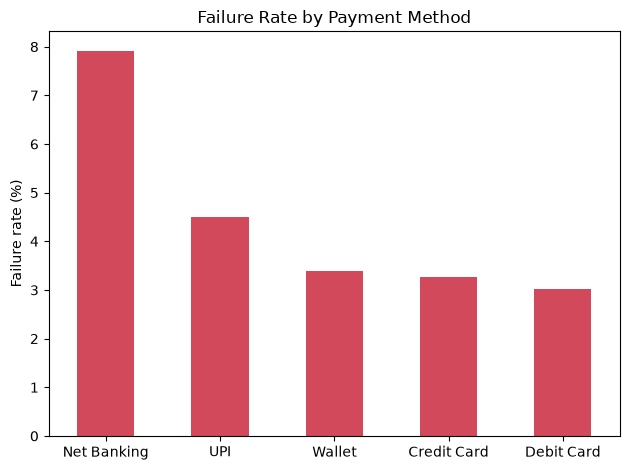

In [34]:
fail_rate.sort_values(ascending=False).plot(kind="bar", color="#d1495b")
plt.title("Failure Rate by Payment Method")
plt.ylabel("Failure rate (%)")
plt.xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("outputs/failure_by_method.png", dpi=150)
plt.show()

## Insight: Payment failures

Net Banking has the highest failure rate at 7.92%, about 2.6 times higher than Debit Card (3.01%).

**Recommendation:** Improve the reliability of the Net Banking payment flow, and suggest UPI as a backup option when a payment fails.

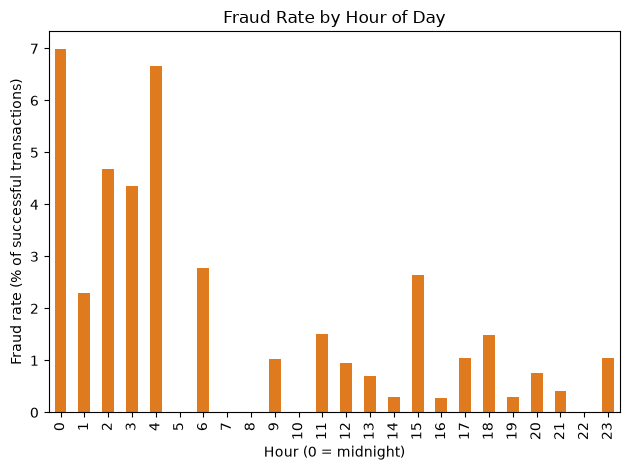

In [35]:
fraud_hour.plot(kind="bar", color="#e07a1f")
plt.title("Fraud Rate by Hour of Day")
plt.ylabel("Fraud rate (% of successful transactions)")
plt.xlabel("Hour (0 = midnight)")
plt.tight_layout()
plt.savefig("outputs/fraud_by_hour.png", dpi=150)
plt.show()

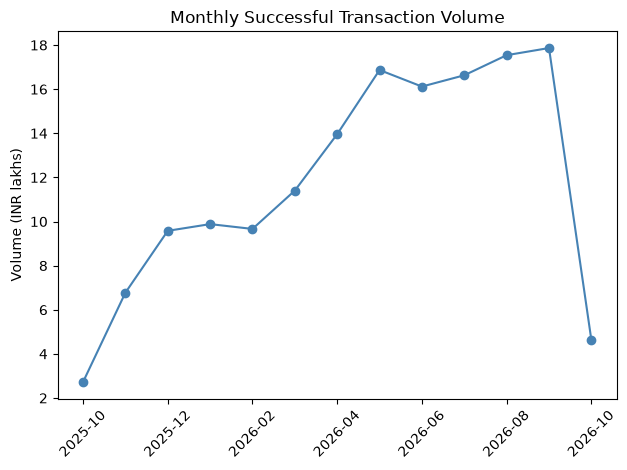

In [36]:
(monthly / 100000).plot(kind="line", marker="o", color="steelblue")
plt.title("Monthly Successful Transaction Volume")
plt.ylabel("Volume (INR lakhs)")
plt.xlabel("")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("outputs/monthly_volume.png", dpi=150)
plt.show()

In [37]:
cat_volume = ok.groupby("category")["amount_inr"].sum().sort_values(ascending=False)
(cat_volume / 100000).round(2)

category
Loan EMI             36.80
Travel               33.32
Investments          27.44
Shopping             19.32
Bills & Utilities    13.22
Groceries             8.82
Healthcare            7.18
Food Delivery         3.58
Entertainment         2.79
Uncategorised         1.18
Name: amount_inr, dtype: float64

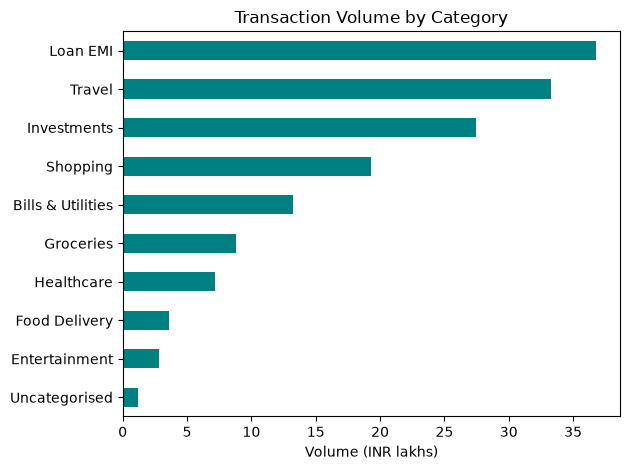

In [38]:
(cat_volume / 100000).plot(kind="barh", color="teal")
plt.title("Transaction Volume by Category")
plt.xlabel("Volume (INR lakhs)")
plt.ylabel("")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("outputs/category_volume.png", dpi=150)
plt.show()

In [39]:
df["timestamp"].max()

Timestamp('2026-10-08 23:20:32')

In [40]:
df["month"].value_counts().sort_index()

month
2025-10    102
2025-11    223
2025-12    288
2026-01    336
2026-02    310
2026-03    417
2026-04    458
2026-05    521
2026-06    524
2026-07    528
2026-08    558
2026-09    568
2026-10    167
Name: count, dtype: int64

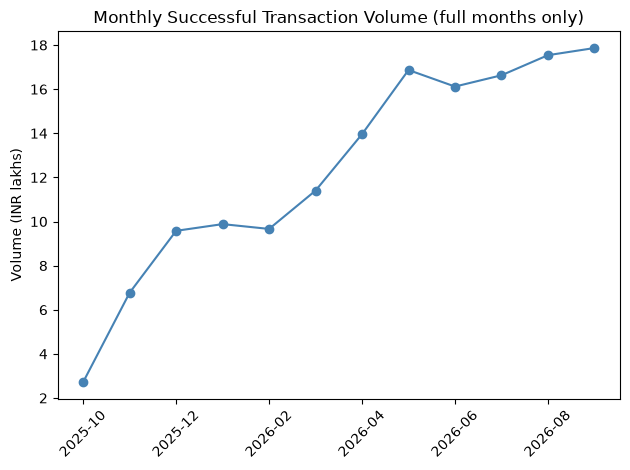

In [41]:
monthly_full = monthly.iloc[:-1]
(monthly_full / 100000).plot(kind="line", marker="o", color="steelblue")
plt.title("Monthly Successful Transaction Volume (full months only)")
plt.ylabel("Volume (INR lakhs)")
plt.xlabel("")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("outputs/monthly_volume.png", dpi=150)
plt.show()

In [42]:
ok = df[df["status"] == "Success"].copy()
ok["late_night"] = ok["hour"] < 5
(ok.groupby("late_night")["is_fraud"].mean() * 100).round(2)

late_night
False    0.88
True     4.88
Name: is_fraud, dtype: float64

## Insight: Late-night fraud

Transactions between midnight and 5 AM have a fraud rate of 4.88%, about 5.5 times higher than the rest of the day (0.88%).

**Recommendation:** Add extra verification, such as an OTP or a transaction limit, for late-night payments.